# Economic narratives and consumer sentiment

**Panagiotis Housos | ph2606 | AI Applications in Finance | Final Project**

Information cutoff: October 13, 2026. Human validation is not completed; independent AI reviews are explicitly separate. Acquisition and model scoring run separately. The cells below rerun analysis from local frozen inputs. Raw datasets are excluded from Git under the established submission policy.

In [1]:
from pathlib import Path
import json
import hashlib
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
assert (ROOT / 'src/economics.py').exists(), 'Execute from the project root.'
expected_inputs = {'data/processed/monthly_dataset.csv': '8cfeac44c5132ab25883598bf3d4a0ad84cd10f6b7f5af43b8d16e55127f9b6a', 'data/processed/media_monthly.csv': '9643fa2ad6052d7f66020737aa2d2fd65f22362d1969f1fec623549cb5fc91fa', 'outputs/tables/provider_bias.csv': '06e999b8b87368f37891f4a25c347bf63ccd3e00278a513dfcc68cb3d3efeeb9', 'data/processed/investment_prices.csv': '2c86cd2c3bcd7441b5ccf29247a90c8832d30aff8477fd622001441cfddf1401', 'data/processed/media_scores.csv': 'c8ea6ce87cf91290c688b30854cdb37ddaa9dbf62f275494593fedb15626d2ab', 'data/processed/bias_trading_prices.csv': '0f0c755611c96bf958d42b959c0875d86a11402deba719bb7578dc77afe0aff8'}
for name, expected in expected_inputs.items():
    path = ROOT / name
    assert path.exists(), f'Acquire required input: {name}'
    assert hashlib.sha256(path.read_bytes()).hexdigest() == expected, f'Input changed: {name}. Rerun analysis and rebuild deliverables before executing this notebook.'
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', 70)
pd.set_option('display.precision', 4)

## Recompute the frozen empirical analysis

The economic feature matrix uses historical ALFRED snapshots. Media reconstruction is retrospective and subject to source selection and original-wording limitations. The package never invents missing records, exposure or human labels.

In [2]:
import subprocess, sys
for command in [['scripts/03_analyze.py'], ['-m', 'src.dynamics'], ['-m', 'src.investing', 'analyze'], ['-m', 'src.bias_trading', 'analyze']]:
    result = subprocess.run([sys.executable, *command], cwd=ROOT, capture_output=True, text=True)
    print(result.stdout)
    assert result.returncode == 0, result.stderr
print('Primary analysis and exploratory dynamics recalculated from acquired observations.')

{
  "cutoff": "2026-10-13",
  "macro_timing": "Actual ALFRED historical vintages on the first calendar day of every forecast month; within-day release time not resolved, interpret origin as end of that day.",
  "target_limitation": "Official Michigan final historical tables, not historical target vintages; partial target revision leakage cannot be excluded.",
  "gdp_treatment": "No interpolation: predictor is growth of last quarterly real GDP observation present in each vintage.",
  "interval_caution": "Approximate HAC parameter + residual intervals; empirical past-OOS-error intervals after 24 calibration observations. Report realized coverage; no guarantee under structural breaks.",
  "latest_final_forecast": {
    "month": "2026-09-01",
    "prediction_date": "2026-09-01",
    "target": "sentiment",
    "model": "M1_economic",
    "observed": 48.1,
    "prediction": 70.66545331146001,
    "gap": -22.56545331146001,
    "error": -22.56545331146001,
    "lower_95": 50.2316036338248,
  

{
  "pool_n": 80,
  "holdout_n": 44,
  "metrics": [
    {
      "model": "D_macro",
      "n": 44,
      "start": "2023-02-01T00:00:00.000",
      "end": "2026-09-01T00:00:00.000",
      "rmse": 4.3005264839,
      "mae": 3.498214615,
      "mean_error": 0.2859605397,
      "analysis_status": "exploratory",
      "rmse_gain_percent_vs_baseline": null,
      "comparison_baseline": null
    },
    {
      "model": "D_macro_AR",
      "n": 44,
      "start": "2023-02-01T00:00:00.000",
      "end": "2026-09-01T00:00:00.000",
      "rmse": 4.2226540069,
      "mae": 3.4241520681,
      "mean_error": 0.236443637,
      "analysis_status": "exploratory",
      "rmse_gain_percent_vs_baseline": null,
      "comparison_baseline": null
    },
    {
      "model": "D_macro_AR_media",
      "n": 44,
      "start": "2023-02-01T00:00:00.000",
      "end": "2026-09-01T00:00:00.000",
      "rmse": 4.2234114057,
      "mae": 3.3866487028,
      "mean_error": 0.2249447442,
      "analysis_status": "explor

                   label  net_total_return  net_cagr  max_drawdown  average_equity_weight
Macro + trend allocation          0.880100  0.055209     -0.201055               0.634109
        SPY buy-and-hold          3.537800  0.137393     -0.337173               1.000000
       Treasury-bill ETF          0.252940  0.019379     -0.002309               0.000000
             Fixed 60/40          1.801621  0.091650     -0.207803               0.600947
{
  "hac_tests": {
    "primary_minus_static": {
      "annualized_daily_intercept": -0.03480351865098805,
      "lower_95": -0.06372102984216918,
      "upper_95": -0.005886007459806919,
      "pvalue": 0.01832897913462651,
      "n": 2955,
      "market_beta": null,
      "method": "OLS HAC(21); annualized arithmetic daily intercept"
    },
    "bil_relative_market_model": {
      "annualized_daily_intercept": -0.017837458040149648,
      "lower_95": -0.048388109862808365,
      "upper_95": 0.012713193782509074,
      "pvalue": 0.252476657251

                   label  net_cagr  net_total_return  max_drawdown  terminal_value_10000
            Fade the gap  0.065893          0.435196     -0.637349          14351.956134
          Follow the gap -0.257559         -0.814773     -0.890736           1852.274978
         Wait for a turn  0.059449          0.386753     -0.344259          13867.528694
      S&P 500 fund (SPY)  0.146955          1.173418     -0.244964          21734.177601
Treasury-bill fund (BIL)  0.031831          0.194127     -0.002200          11941.269090
     Always 3x up (UPRO)  0.270409          2.877175     -0.639431          38771.745866
   Always 3x down (SPXU) -0.363757         -0.922707     -0.927405            772.925422
   Half UPRO / half SPXU -0.014579         -0.079791     -0.135153           9202.092113
       60% SPY / 40% BIL  0.101960          0.732757     -0.149856          17327.571466
Fund decisions: {"Fade_gap": {"UPRO": 38, "SPXU": 29, "BIL": 1}, "Follow_gap": {"SPXU": 38, "UPRO": 29, "BIL":

## Persistence and differenced-model sensitivity

These checks were added after the primary analysis and are exploratory. ADF and KPSS have different null hypotheses; structural breaks limit either interpretation. The differenced models use the same 44 test months and a separately identified two-contrast loss-test family.

In [3]:
display(pd.read_csv(ROOT / 'outputs/tables/dynamics_unit_root.csv'))
display(pd.read_csv(ROOT / 'outputs/tables/dynamics_differenced_metrics.csv'))
display(pd.read_csv(ROOT / 'outputs/tables/dynamics_loss_hac.csv'))

,sample,variable,n,start,end,lag1_correlation,adf_statistic,...,kpss_statistic,kpss_pvalue_tabulated,kpss_pvalue_boundary,kpss_lags_auto,adf_null,kpss_null,interpretation
0,historical,sentiment,201,2010-01-01,2026-09-01,0.9592,-0.4018,...,0.7236,0.0114,within tabulated range,9,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
1,historical,unemployment,201,2010-01-01,2026-09-01,0.9363,-2.8838,...,1.2641,0.0100,p < 0.01,9,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
2,historical,pce_yoy,201,2010-01-01,2026-09-01,0.9824,-1.9677,...,0.7878,0.0100,p < 0.01,9,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
3,historical,gdp_qoq_annualized,201,2010-01-01,2026-09-01,0.5635,-4.3157,...,0.0246,0.1000,p > 0.10,1,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
4,historical,price_36m,201,2010-01-01,2026-09-01,0.9956,-1.4358,...,1.1486,0.0100,p < 0.01,9,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
5,historical,real_income_yoy,201,2010-01-01,2026-09-01,0.3700,-4.5556,...,0.0879,0.1000,p > 0.10,8,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
6,historical,media_tone_lag1,80,2020-02-01,2026-09-01,0.2231,-7.0025,...,0.1979,0.1000,p > 0.10,3,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
7,historical,delta_sentiment,200,2010-02-01,2026-09-01,0.0727,-8.8224,...,0.2467,0.1000,p > 0.10,10,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
8,common_media_pool,sentiment,80,2020-02-01,2026-09-01,0.8960,-0.7997,...,0.8270,0.0100,p < 0.01,5,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
9,common_media_pool,unemployment,80,2020-02-01,2026-09-01,0.8189,-2.2066,...,0.5596,0.0282,within tabulated range,5,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...


,model,n,start,end,rmse,mae,mean_error,analysis_status,rmse_gain_percent_vs_baseline,comparison_baseline
0,D_macro,44,2023-02-01,2026-09-01,4.3005,3.4982,0.2860,exploratory,NaN,NaN
1,D_macro_AR,44,2023-02-01,2026-09-01,4.2227,3.4242,0.2364,exploratory,NaN,NaN
2,D_macro_AR_media,44,2023-02-01,2026-09-01,4.2234,3.3866,0.2249,exploratory,-0.0179,D_macro_AR
3,D_macro_media,44,2023-02-01,2026-09-01,4.2729,3.4134,0.2692,exploratory,0.6418,D_macro


,family,augmented,baseline,n,start,end,hac_maxlags,primary_bandwidth,mean_squared_loss_difference,hac_se_mean_loss_difference,hac_pvalue_two_sided,family_size,interpretation,bh_qvalue_within_bandwidth_family
0,original_three_contrasts_bandwidth_sensitivity,M2_economic_media,M1_economic,44,2023-02-01,2026-09-01,3,True,-0.2245,3.5024,0.9489,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9489
1,original_three_contrasts_bandwidth_sensitivity,M3_economic_media_controls,M1_controls,44,2023-02-01,2026-09-01,3,True,-1.3620,5.3445,0.7988,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9489
2,original_three_contrasts_bandwidth_sensitivity,AR_macro_media,AR_macro,44,2023-02-01,2026-09-01,3,True,-0.4142,0.9502,0.6629,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9489
3,original_three_contrasts_bandwidth_sensitivity,M2_economic_media,M1_economic,44,2023-02-01,2026-09-01,6,False,-0.2245,3.0742,0.9418,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9418
4,original_three_contrasts_bandwidth_sensitivity,M3_economic_media_controls,M1_controls,44,2023-02-01,2026-09-01,6,False,-1.3620,4.8012,0.7767,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9418
5,original_three_contrasts_bandwidth_sensitivity,AR_macro_media,AR_macro,44,2023-02-01,2026-09-01,6,False,-0.4142,1.0104,0.6818,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9418
6,original_three_contrasts_bandwidth_sensitivity,M2_economic_media,M1_economic,44,2023-02-01,2026-09-01,12,False,-0.2245,2.7289,0.9344,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9344
7,original_three_contrasts_bandwidth_sensitivity,M3_economic_media_controls,M1_controls,44,2023-02-01,2026-09-01,12,False,-1.3620,3.5679,0.7027,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9344
8,original_three_contrasts_bandwidth_sensitivity,AR_macro_media,AR_macro,44,2023-02-01,2026-09-01,12,False,-0.4142,1.0795,0.7012,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9344
9,exploratory_differenced_two_contrasts,D_macro_media,D_macro,44,2023-02-01,2026-09-01,3,True,-0.2366,0.7519,0.7530,2,Exploratory nested-model loss comparison; limited sample; not causal,0.9910


## Independent AI diagnostic: class and source concordance

These are AI development references, not human ground truth. The original pool has 300 items; final-corpus eligibility and mixed/uncertain exclusions are explicit. Small source/class cells have unstable estimates. Required human validation remains pending.

In [4]:
path = ROOT / 'outputs/ai_diagnostic_validation_metrics.json'
ai = json.loads(path.read_text()) if path.exists() else {}
if ai:
    display(pd.Series({k: ai.get(k) for k in ['label_type','completed_independent_pairs','tone_agreement','tone_cohens_kappa','annotation_pool_final_eligible_n','annotation_pool_final_excluded_n','human_specific_requirement_satisfied']}))
    rows, classes = [], []
    for annotator, models in ai['model_reference_concordance'].items():
        for model, entry in models.items():
            for source, result in entry['by_source'].items():
                rows.append({'reference': annotator, 'model': model, 'source': source, 'n': result['n'], 'agreement': result['agreement'], 'macro_F1_concordance': result['macro_f1_reference_concordance']})
            for label, result in entry['class_concordance'].items():
                classes.append({'reference': annotator, 'model': model, 'class': label, **result})
    display(pd.DataFrame(rows))
    display(pd.DataFrame(classes))
else:
    print('Independent AI diagnostic inputs are unavailable in this clone; no human labels are inferred.')

label_type                              ai_diagnostic
completed_independent_pairs                       300
tone_agreement                                   0.92
tone_cohens_kappa                              0.8895
annotation_pool_final_eligible_n                  277
annotation_pool_final_excluded_n                   23
human_specific_requirement_satisfied            False
dtype: object

,reference,model,source,n,agreement,macro_F1_concordance
0,annotator_a,contextual,Associated Press,35,0.7143,0.6919
1,annotator_a,contextual,Colorado Sun,37,0.8108,0.7821
2,annotator_a,contextual,Gothamist,31,0.7742,0.7643
3,annotator_a,contextual,Hacker News,36,0.7500,0.7355
4,annotator_a,contextual,NPR,36,0.7500,0.7394
5,annotator_a,contextual,Reuters,36,0.6667,0.6257
6,annotator_a,contextual,Texas Tribune,31,0.6452,0.5556
7,annotator_a,dictionary,Associated Press,35,0.6857,0.6646
8,annotator_a,dictionary,Colorado Sun,37,0.5946,0.5722
9,annotator_a,dictionary,Gothamist,31,0.4839,0.4593


,reference,model,class,precision,recall,f1,support
0,annotator_a,contextual,negative,0.9362,0.7273,0.8186,121
1,annotator_a,contextual,neutral,0.4024,0.8049,0.5366,41
2,annotator_a,contextual,positive,0.8485,0.7000,0.7671,80
3,annotator_a,dictionary,negative,0.8602,0.6612,0.7477,121
4,annotator_a,dictionary,neutral,0.3077,0.5854,0.4034,41
5,annotator_a,dictionary,positive,0.6901,0.6125,0.6490,80
6,annotator_b,contextual,negative,0.9570,0.7120,0.8165,125
7,annotator_b,contextual,neutral,0.3780,0.7561,0.5041,41
8,annotator_b,contextual,positive,0.7794,0.6883,0.7310,77
9,annotator_b,dictionary,negative,0.8913,0.6560,0.7558,125


## Political-name and source-label stress tests

The original text is held constant except for the specified change. Changed names can change meaning. Class switches do not prove political discrimination or factual bias.

In [5]:
media_summary = json.loads((ROOT / 'outputs/media_summary.json').read_text())
display(pd.DataFrame(media_summary['perturbation']['variant_comparisons']))
print('Source-prefix paired mean absolute tone difference:', media_summary['perturbation']['source_pair_mean_absolute_delta'])
print('Factual-calibration status:', media_summary.get('factual_calibration'))

,test,n,mean_absolute_tone_delta,class_switch_rate
0,political_name_swap,100,0.0760,0.05
1,source_prefix_Gothamist,100,0.1021,0.12
2,source_prefix_Reuters,100,0.0830,0.12


Source-prefix paired mean absolute tone difference: 0.05627288064146129
Factual-calibration status: {'numeric_eligible_titles': 313, 'purposive_same_release_day_values_checked': 8, 'numerically_aligned': 8, 'population_factual_error_rate': None, 'fully_verified_definition_period_and_intraday_vintage_claims': 0, 'interpretation': 'Eight purposive unemployment-title percentages match archived official release values; this is numeric alignment, not an estimate of overall factual accuracy. Most titles omit precise definition or period; RSS intraday timestamps are unreliable. No factual-error rate is estimated.', 'checks_path': 'data/processed/factual_calibration_checks.csv', 'benchmarks_path': 'data/raw/media/official_claim_benchmarks.json'}


## News-provider comparison: matched official releases

A separate supplemental sample includes CNBC and Fox brands. The provider bars use a common set of releases and a defined peer reference. This is a relative negative-framing proxy, not a factual or ideological rating. The original forecast corpus and 300-title AI review remain separate; the new providers do not have independent human validation.

In [6]:
provider_table = pd.read_csv(ROOT / 'outputs/tables/provider_bias.csv')
display(provider_table)
provider_summary = json.loads((ROOT / 'outputs/tables/provider_bias_summary.json').read_text())
display(pd.Series(provider_summary, name='provider_comparison_protocol'))

,provider,bias_pp,lower_95,upper_95,raw_percentile_lower_95,raw_percentile_upper_95,n_titles,...,one_hash_title_bias_pp,event_bootstrap_lower_95,event_bootstrap_upper_95,coverage,same_common_events,comparison_status,ci_contains_zero
0,Associated Press,NaN,NaN,NaN,NaN,NaN,14,...,NaN,NaN,NaN,0.7222,False,outside_main_common_support_no_comparable_bar,NaN
1,Bloomberg,20.8333,-1.6667,55.0000,-1.6667,55.0000,15,...,2.0000e+01,-1.6667,55.0000,0.3333,True,main_common_event_panel,True
2,CNBC,-9.1667,-19.1667,-0.8333,-19.1667,-0.8333,15,...,-5.9212e-16,-19.1667,-0.8333,0.3333,True,main_common_event_panel,False
3,CNN,0.8333,-10.0000,14.1667,-10.0000,14.1667,9,...,-5.9212e-16,-10.0000,14.1667,0.3333,True,main_common_event_panel,True
4,Fox Business,5.8333,-6.6667,19.1667,-6.6667,19.1667,15,...,-5.9212e-16,-6.6667,19.1667,0.3333,True,main_common_event_panel,True
5,Fox News,-12.5000,-28.3333,-0.8333,-28.3333,-0.8333,8,...,-2.0000e+01,-28.3333,-0.8333,0.3333,True,main_common_event_panel,False
6,NPR,NaN,NaN,NaN,NaN,NaN,19,...,NaN,NaN,NaN,0.7222,False,outside_main_common_support_no_comparable_bar,NaN
7,Reuters,NaN,NaN,NaN,NaN,NaN,23,...,NaN,NaN,NaN,0.8889,False,outside_main_common_support_no_comparable_bar,NaN
8,Wall Street Journal,-5.8333,-12.5000,-0.8333,-12.5000,-0.8333,10,...,-5.9212e-16,-12.5000,-0.8333,0.3333,True,main_common_event_panel,False


status                                                                                                    complete
metric_name                                               same-event relative negative framing (percentage points)
formula                                      100 * mean_e[negative-title share(provider,e) - mean_other_provide...
interpretation                               Higher means more sampled titles classified negative than same-eve...
interval_interpretation                      Conditional95% month-resampling stability ranges for this fixed sa...
affiliation_note                             Fox News and Fox Business are separate queried brands with shared ...
not_measured                                 [factual inaccuracy, partisan or ideological bias, intent, audienc...
mode                                                                          identical_common_events_equal_weight
main_providers                                 [CNBC, Fox News, Fox Business, CN

## Retrospective investment extension (October 17)

The primary macro/trend rule was fixed before performance calculation; the simpler monthly 60% SPY / 40% BIL benchmark is preferred after the comparison. Neither is an untouched holdout. Costs include entry, exit and both traded legs. Gap and media overlays use retrospective inputs. All 44 gaps are negative; this is exposure, not demonstrated timing.

In [7]:
investment = json.loads((ROOT / 'outputs/tables/investment_summary.json').read_text())
performance = pd.read_csv(ROOT / 'outputs/tables/investment_metrics.csv')
display(performance.loc[performance.cost_bps.eq(10)])
print('Full-period cost sensitivity:')
display(performance.loc[performance['sample'].eq('full'), ['model','cost_bps','net_cagr','max_drawdown','annual_gross_turnover']])
print('Primary HAC diagnostics:')
display(pd.DataFrame(investment['hac_tests']).T)
print('Original two-test overlay family (unadjusted for exposure):')
display(pd.DataFrame(investment['overlay_tests']))
print('Post-result exposure diagnosis:')
print(json.dumps(investment['exposure_diagnostics'], indent=2))
print(investment['practical_conclusion'])

,sample,model,label,cost_bps,allocation_periods,start,end,...,net_cagr,volatility,max_drawdown,average_equity_weight,annual_gross_turnover,bil_relative_sharpe,terminal_value_10000
4,full,Macro_trend_80_20,Macro + trend allocation,10,141,2015-01-02,2026-10-02,...,0.0552,0.0955,-0.2011,0.6341,3.0866,0.4085,18801.0005
5,full,SPY_hold,SPY buy-and-hold,10,141,2015-01-02,2026-10-02,...,0.1374,0.1753,-0.3372,1.0000,0.1702,0.7131,45377.9997
6,full,BIL_hold,Treasury-bill ETF,10,141,2015-01-02,2026-10-02,...,0.0194,0.0027,-0.0023,0.0000,0.1702,-0.4131,12529.3950
7,full,Static_60_40,Fixed 60/40,10,141,2015-01-02,2026-10-02,...,0.0917,0.1034,-0.2078,0.6009,0.3705,0.7138,28016.2076
18,common_44,Macro_trend_80_20,Macro + trend allocation,10,44,2023-02-02,2026-10-02,...,0.1231,0.0949,-0.0836,0.6924,3.8789,0.8043,15299.5329
19,common_44,SPY_hold,SPY buy-and-hold,10,44,2023-02-02,2026-10-02,...,0.1970,0.1486,-0.1876,1.0000,0.5457,0.9872,19321.8116
20,common_44,BIL_hold,Treasury-bill ETF,10,44,2023-02-02,2026-10-02,...,0.0449,0.0025,-0.0010,0.0000,0.5457,-0.7406,11746.8588
21,common_44,Static_60_40,Fixed 60/40,10,44,2023-02-02,2026-10-02,...,0.1353,0.0882,-0.1133,0.6011,0.7045,0.9805,15918.5193
22,common_44,Gap_overlay,Exploratory gap tilt,10,44,2023-02-02,2026-10-02,...,0.1382,0.1082,-0.1026,0.7923,3.8448,0.8415,16067.6806
23,common_44,Media_overlay,Exploratory media tilt,10,44,2023-02-02,2026-10-02,...,0.1080,0.0825,-0.0712,0.5949,4.0147,0.7470,14560.2066


Full-period cost sensitivity:


,model,cost_bps,net_cagr,max_drawdown,annual_gross_turnover
0,Macro_trend_80_20,0,0.0585,-0.1953,3.0883
1,SPY_hold,0,0.1376,-0.3372,0.1702
2,BIL_hold,0,0.0196,-0.0021,0.1702
3,Static_60_40,0,0.0921,-0.2078,0.3706
4,Macro_trend_80_20,10,0.0552,-0.2011,3.0866
5,SPY_hold,10,0.1374,-0.3372,0.1702
6,BIL_hold,10,0.0194,-0.0023,0.1702
7,Static_60_40,10,0.0917,-0.2078,0.3705
8,Macro_trend_80_20,25,0.0503,-0.2096,3.0839
9,SPY_hold,25,0.1371,-0.3372,0.1700


Primary HAC diagnostics:


,annualized_daily_intercept,lower_95,upper_95,pvalue,n,market_beta,method
primary_minus_static,-0.0348,-0.0637,-0.0059,0.0183,2955,None,OLS HAC(21); annualized arithmetic daily intercept
bil_relative_market_model,-0.0178,-0.0484,0.0127,0.2525,2955,0.4542,OLS HAC(21); annualized arithmetic daily intercept


Original two-test overlay family (unadjusted for exposure):


,model,annualized_daily_intercept,lower_95,upper_95,pvalue,n,market_beta,method,bh_qvalue
0,Gap_overlay,0.0148,0.0020,0.0275,0.0233,920,None,OLS HAC(21); annualized arithmetic daily intercept,0.0233
1,Media_overlay,-0.0147,-0.0272,-0.0021,0.0223,920,None,OLS HAC(21); annualized arithmetic daily intercept,0.0233


Post-result exposure diagnosis:
{
  "status": "post-result explanatory diagnostics; conditional HAC inference, not an additional confirmatory family",
  "gap_negative_origins": 44,
  "media_negative_origins": 43,
  "origins": 44,
  "beta_adjusted_overlay_differences": [
    {
      "model": "Gap_overlay",
      "annualized_daily_intercept": 0.0001776593035039356,
      "lower_95": -2.899781088285041e-05,
      "upper_95": 0.0003843164178907216,
      "pvalue": 0.0919992162763555,
      "n": 920,
      "market_beta": 0.09910694116864897,
      "method": "OLS HAC(21); annualized arithmetic daily intercept"
    },
    {
      "model": "Media_overlay",
      "annualized_daily_intercept": -0.0005203498320996874,
      "lower_95": -0.002305944622293636,
      "upper_95": 0.0012652449580942615,
      "pvalue": 0.5678886808357619,
      "n": 920,
      "market_beta": -0.09601121303001092,
      "method": "OLS HAC(21); annualized arithmetic daily intercept"
    }
  ],
  "interpretation": "All n

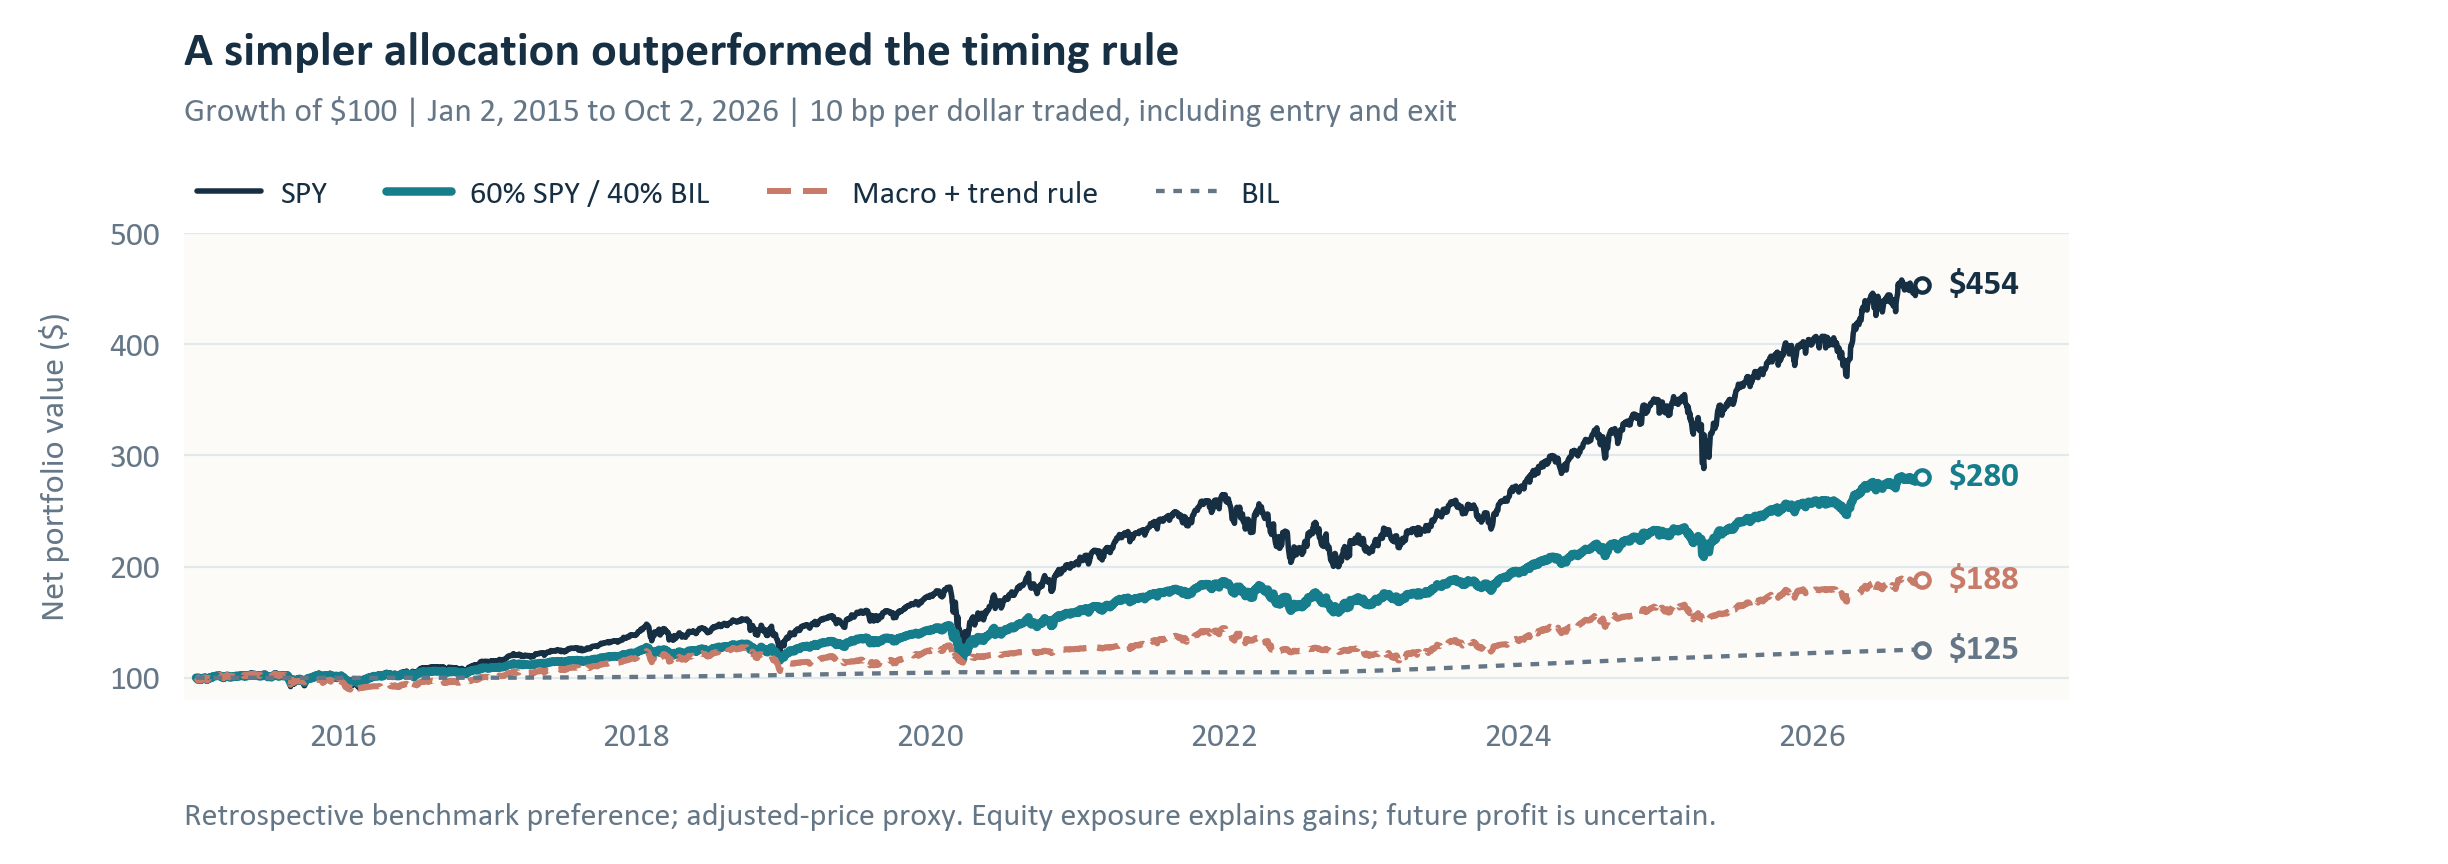

In [8]:
display(Image(filename=str(ROOT / 'outputs/investment_strategy.png')))

## Three aggressive strategies that use only earlier news wording

A strategy is a rule for choosing what to buy. These three ideas use the same national-minus-local negative-wording score. None uses economic releases, survey answers or stock-price trends to choose funds. UPRO aims for three times the S&P 500's DAILY move; SPXU aims for three times the opposite DAILY move. These are risky daily targets, not promises for an entire month. Their actual historical fund prices are used. The fixed rules, current-month exclusion, costs and all benchmark results appear below. A losing idea is retained. These historical simulations do not establish verified bias or a future investment advantage.

In [9]:
bias = json.loads((ROOT / 'outputs/tables/bias_trading_summary.json').read_text())
bias_metrics = pd.read_csv(ROOT / 'outputs/tables/bias_trading_metrics.csv')
print('All rules and all benchmarks, on exactly the same dates:')
display(bias_metrics.loc[bias_metrics.cost_bps.eq(10)])
print('Cost sensitivity for the three ideas:')
display(bias_metrics.loc[bias_metrics['sample'].eq('full') & bias_metrics.model.isin(bias['rule_names']), ['model','cost_bps','net_cagr','net_total_return','max_drawdown','terminal_value_10000']])
print('How often each rule chose each fund:')
display(pd.DataFrame(bias['rule_fund_counts']).fillna(0).astype(int))
print('Three historical return comparisons, with Holm correction (not alpha tests):')
display(pd.DataFrame(bias['tests_vs_spy']))
print('Signal inputs only:', bias['signal_inputs_only'])
print('Limitations:', *bias['limitations'], sep='\n- ')

All rules and all benchmarks, on exactly the same dates:


,sample,model,label,cost_bps,allocation_periods,start,end,...,terminal_value_10000,annual_gross_turnover,orders,average_weight_UPRO,average_weight_SPXU,average_weight_SPY,average_weight_BIL
9,full,Fade_gap,Fade the gap,10,68,2021-02-02,2026-10-02,...,14351.9561,13.7628,78,0.5608,0.4238,0.0000,0.0155
10,full,Follow_gap,Follow the gap,10,68,2021-02-02,2026-10-02,...,1852.2750,13.7628,78,0.4238,0.5608,0.0000,0.0155
11,full,Wait_turn,Wait for a turn,10,68,2021-02-02,2026-10-02,...,13867.5287,8.1166,46,0.1202,0.0738,0.0000,0.8060
12,full,SPY_hold,S&P 500 fund (SPY),10,68,2021-02-02,2026-10-02,...,21734.1776,0.3531,2,0.0000,0.0000,1.0000,0.0000
13,full,BIL_hold,Treasury-bill fund (BIL),10,68,2021-02-02,2026-10-02,...,11941.2691,0.3531,2,0.0000,0.0000,0.0000,1.0000
14,full,UPRO_hold,Always 3x up (UPRO),10,68,2021-02-02,2026-10-02,...,38771.7459,0.3531,2,1.0000,0.0000,0.0000,0.0000
15,full,SPXU_hold,Always 3x down (SPXU),10,68,2021-02-02,2026-10-02,...,772.9254,0.3531,2,0.0000,1.0000,0.0000,0.0000
16,full,Two_sided_50_50,Half UPRO / half SPXU,10,68,2021-02-02,2026-10-02,...,9202.0921,1.5814,138,0.5046,0.4954,0.0000,0.0000
17,full,Static_60_40,60% SPY / 40% BIL,10,68,2021-02-02,2026-10-02,...,17327.5715,0.5496,138,0.0000,0.0000,0.6006,0.3994
36,2021_2023,Fade_gap,Fade the gap,10,35,2021-02-02,2024-01-02,...,12968.5826,12.3461,36,0.6576,0.3424,0.0000,0.0000


Cost sensitivity for the three ideas:


,model,cost_bps,net_cagr,net_total_return,max_drawdown,terminal_value_10000
0,Fade_gap,0,0.0807,0.5516,-0.6352,15516.2254
1,Follow_gap,0,-0.2473,-0.7997,-0.8847,2002.5365
2,Wait_turn,0,0.0681,0.4520,-0.3416,14520.3347
9,Fade_gap,10,0.0659,0.4352,-0.6373,14351.9561
10,Follow_gap,10,-0.2576,-0.8148,-0.8907,1852.2750
11,Wait_turn,10,0.0594,0.3868,-0.3443,13867.5287
18,Fade_gap,25,0.0441,0.2767,-0.6406,12767.2828
19,Follow_gap,25,-0.2727,-0.8352,-0.8992,1647.7558
20,Wait_turn,25,0.0466,0.2943,-0.3482,12942.9316


How often each rule chose each fund:


,Fade_gap,Follow_gap,Wait_turn
UPRO,38,29,8
SPXU,29,38,5
BIL,1,1,55


Three historical return comparisons, with Holm correction (not alpha tests):


,model,annualized_daily_intercept,lower_95,upper_95,pvalue,n,market_beta,method,holm_pvalue
0,Fade_gap,0.0319,-0.3510,0.4149,0.8702,1424,None,OLS HAC(21); annualized arithmetic daily intercept,0.8702
1,Follow_gap,-0.3311,-0.7565,0.0942,0.1270,1424,None,OLS HAC(21); annualized arithmetic daily intercept,0.3811
2,Wait_turn,-0.0739,-0.2363,0.0885,0.3727,1424,None,OLS HAC(21); annualized arithmetic daily intercept,0.7455


Signal inputs only: ['Reuters negative-headline share', 'NPR negative-headline share', 'Colorado Sun negative-headline share', 'their previous calendar months']
Limitations:
- Relative negative wording is an unvalidated proxy, not verified factual or ideological bias
- Retrospective titles, model availability and revised adjusted prices prevent a historical implementability claim
- Rules were designed after earlier project/market findings; no untouched future test exists
- Very aggressive products can lose nearly all capital; daily reset compounds and monthly holdings differ from 3x monthly market return
- Assumed costs omit taxes, nonlinear impact and investor-specific commissions


## The question and the main findings

People can hear that the economy is growing and still worry about paying their bills. This project asks why. The University of Michigan’s consumer sentiment index is a survey score about people’s finances, business conditions and buying plans. Higher means more optimism. A score of 60 does not mean 60% of people are happy; this index is not a percentage or a scale capped at 100.

We compare three explanations: household pressures missed by national statistics; the stories people see and how those stories are worded; and problems with the data or forecasting model. Artificial intelligence (AI) software labels headline wording. A negative headline can accurately describe bad news, so negative does not automatically mean biased.

The first forecasting model, called M1, uses jobs, prices and national output. For the latest completed month, the actual survey score was 48.1 and M1 predicted 70.7. The gap is actual minus predicted: -22.6 points. For example, an actual score of 60 minus a prediction of 70 gives a gap of −10. A gap is a model’s mistake, not proof that people are irrational.

Across the same 44 test months, adding headline tone lowers the forecast-error score by 0.01 survey points. When the model also knows last month’s survey, headlines lower the score by 0.04 points. This score gives larger mistakes extra weight; page 4 explains the calculation. The gains are tiny; statistical checks do not establish a reliable improvement. Page 11 compares how providers describe the same news.

In [10]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[0][1][4]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,What we use,What it can tell us
0,Economy,"Monthly history from 2010; earlier published versions of the jobs,..."
1,Headlines,"3,787 titles in 82 months; national news, local news and Hacker News"
2,Study date,"Economic information frozen October 13, 2026; October survey/news ..."
3,Accuracy checks,AI checks completed; the required two independent human reviewers ...
4,Investment tests,"Rules, gains, losses and their limits are explained on page 12"


A separate historical simulation applies three text-only trading rules to past prices. Starting with $10,000, two finish near $14,352 and $13,868; one falls to $1,852. All finish below simply holding a broad stock fund, $21,734. These aggressive rules also suffer larger falls along the way. Making some money is not the same as being a good strategy.

## 1. Check what was known at the time

A number’s date can mean the month it describes, not the day people first learned it. Using a later release in an earlier prediction would be like answering a quiz after seeing the answers. The spreadsheet has four separate date/value pairs, so they must be joined by the periods they describe.

Official jobs data come from the Bureau of Labor Statistics (BLS). Prices and output come from the Bureau of Economic Analysis (BEA). Gross domestic product (GDP) means the country’s total economic output. The Personal Consumption Expenditures (PCE) price index tracks consumer prices. The required headline index includes food and energy; the core index leaves them out.

In [11]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[1][1][2]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Spreadsheet issue,What the official records show
0,October survey: 46.3,"A first estimate was released October 9. Keep it for monitoring, s..."
1,July–September GDP: 3.7,"The first official release is October 29, after our cutoff. Do not..."
2,August inflation: 3.00759,All 584 spreadsheet values match core inflation. Required headline...
3,October 2025 unemployment missing,BLS did not collect the household survey during the shutdown. Do n...
4,GDP later revised,September 30 updates cannot enter predictions made before that date.


We use the Federal Reserve’s historical data archive, ALFRED, to recover earlier published versions of the economic numbers. The saved files record request addresses, download times and digital fingerprints that reveal file changes. This makes the economic inputs checkable.

There is still a limit: the downloaded Michigan history contains today’s final survey values, not every version originally published. Old headlines may also have been edited or removed. The notebook saves summary results, while detailed data stay local under the course’s no-data-upload rule. A fresh download may not recover exactly the same sample.

## 2. Build a fair forecast

A forecast is a prediction made before its answer is published. For each target month, we use the economic data available by the end of its first calendar day. We cannot recover every release’s exact hour, so we allow the whole first day. GDP is published quarterly, every three months: keep the latest known quarter until a new release arrives, rather than invent monthly GDP figures.

In [12]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[2][1][1]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Input,Meaning and calculation
0,"Unemployment, official U-3 rate",Share of the labor force without a job and actively seeking work. ...
1,Headline PCE inflation,Percentage price change over twelve months: 100 × (current index /...
2,Real GDP growth,Output growth after allowing for price changes. Main measure: 100 ...
3,Alternative GDP measure,Compare output with the same quarter a year earlier. This is diffe...
4,Household pressures,Add three years of accumulated price increases and growth in after...


The overall survey, its Current Economic Conditions score and its Consumer Expectations score are analyzed separately. Current Economic Conditions describes today; Consumer Expectations asks about the future. These questions cover everyday finances and buying decisions, so unemployment, inflation and GDP cannot be expected to explain everything.

Each model learns from months before its prediction month. A simple comparison repeats last month’s survey score. News enters with a one-month delay, and October’s incomplete news cannot be used to make an October 1 prediction. Some survey interviews began in the previous month, so the prediction is before the published score but not necessarily before every interview.

Each record keeps the period its number describes and the historical data version used. Missing calendar months cannot be skipped when calculating a twelve-month change. The model adds weighted inputs. Ordinary least squares chooses weights to make earlier squared mistakes as small as possible. The notebook includes the formulas, release records and checks; revised survey histories remain a limitation.

## 3. How wrong were the forecasts?

M1 learns from at least 60 earlier months of unemployment, headline inflation and GDP. We test it on later months, then move forward and repeat. This is an out-of-sample test: each answer belongs to a later month than the months used for learning.

Root mean squared error (RMSE) is a forecast-error score, measured here in survey points. Square each mistake, average the squares, then take the square root. Errors of 3 and 4 points give square root of ((9 + 16) / 2) = 3.54. Bigger errors receive extra weight; lower is better.

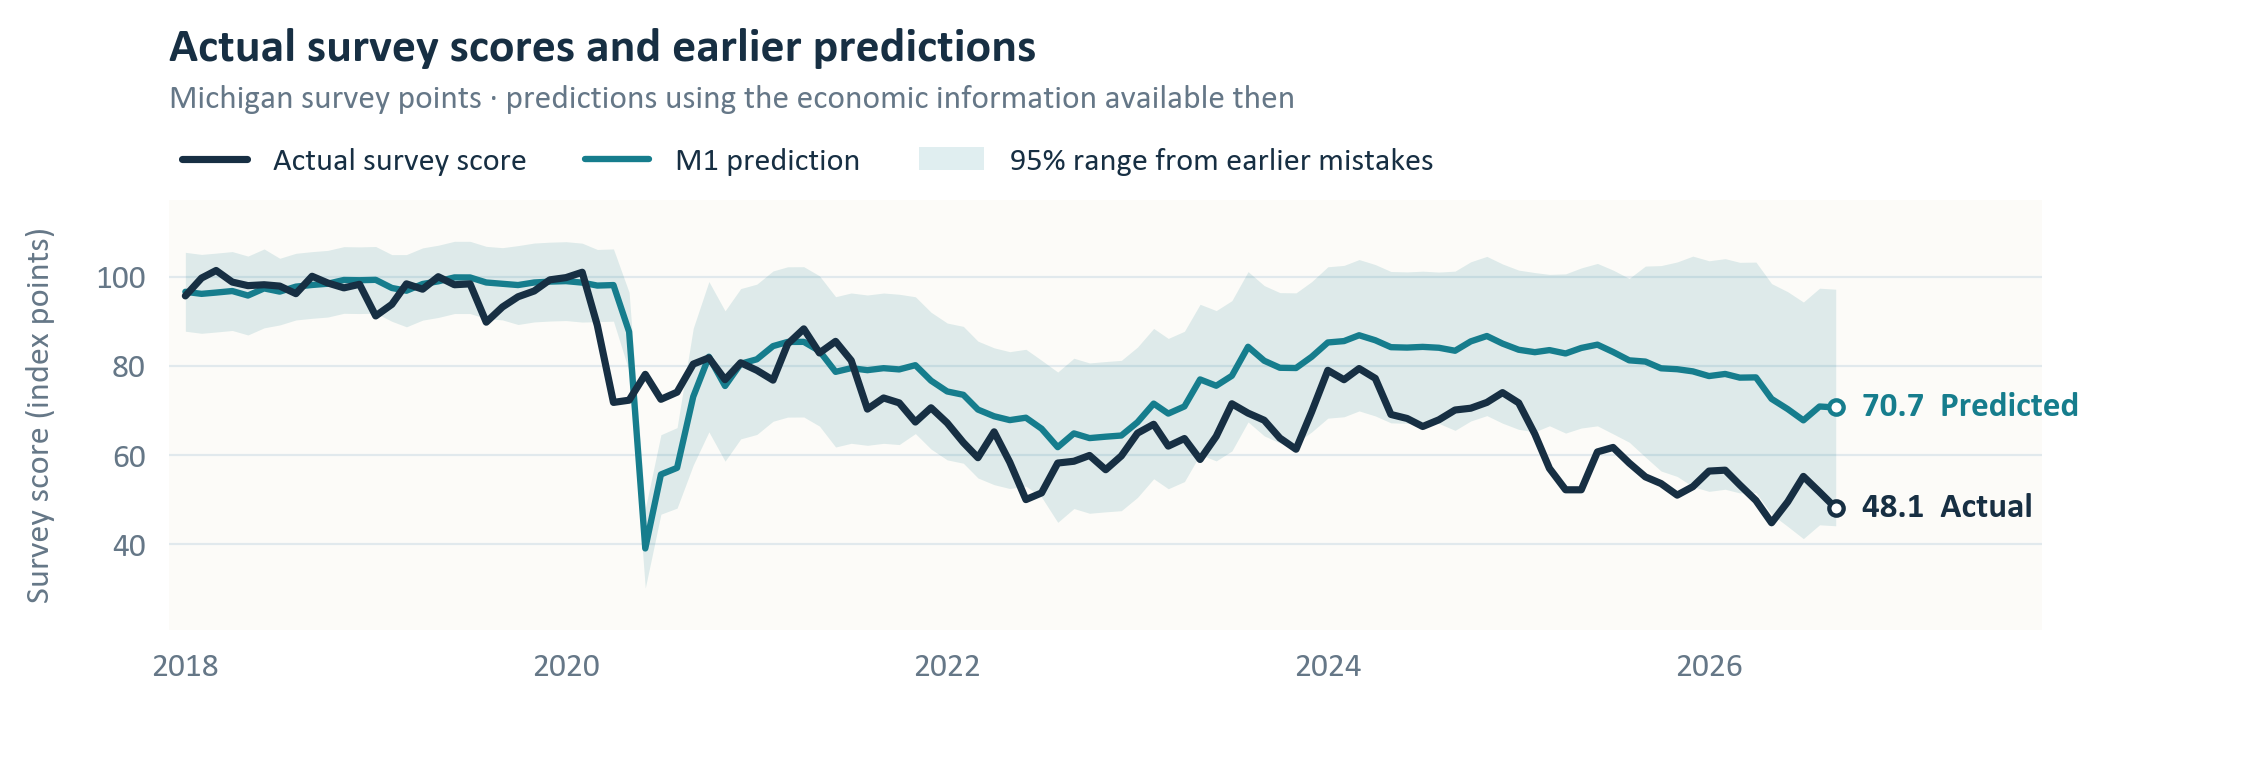

In [13]:
display(Image(filename=str(ROOT / 'outputs' / 'economic_forecast.png')))

The dark line is the actual survey score; the other line is M1’s earlier prediction. The shaded prediction interval is a plausible range based on earlier errors, not a guarantee. An absent band means too little earlier error history.

Across 141 test months, M1’s error score is 12.35 points. Simply repeating last month’s survey scores 4.26, much better. Separate models for current conditions and expectations score 16.50 and 10.44. The three economic inputs alone therefore leave important information out.

A range aimed at 95% coverage should contain the answer about 95 times in 100 comparable tests. M1’s formula-based range covers only 72.3% of outcomes. A range built from earlier errors covers 78.4% of 116 usable tests. September’s 48.1 is below the first range, 50.23–91.10, but inside the second, 44.13–97.21. How unusual the gap looks depends on the uncertainty calculation.

Mistakes in nearby months are related, and relationships changed around the pandemic and inflation surge. The notebook checks shorter learning windows, seasons, different GDP definitions and survey methods. It also lets a model learn from the previous survey rather than assuming three national statistics are enough.

## 4. Other reasons people may feel worse

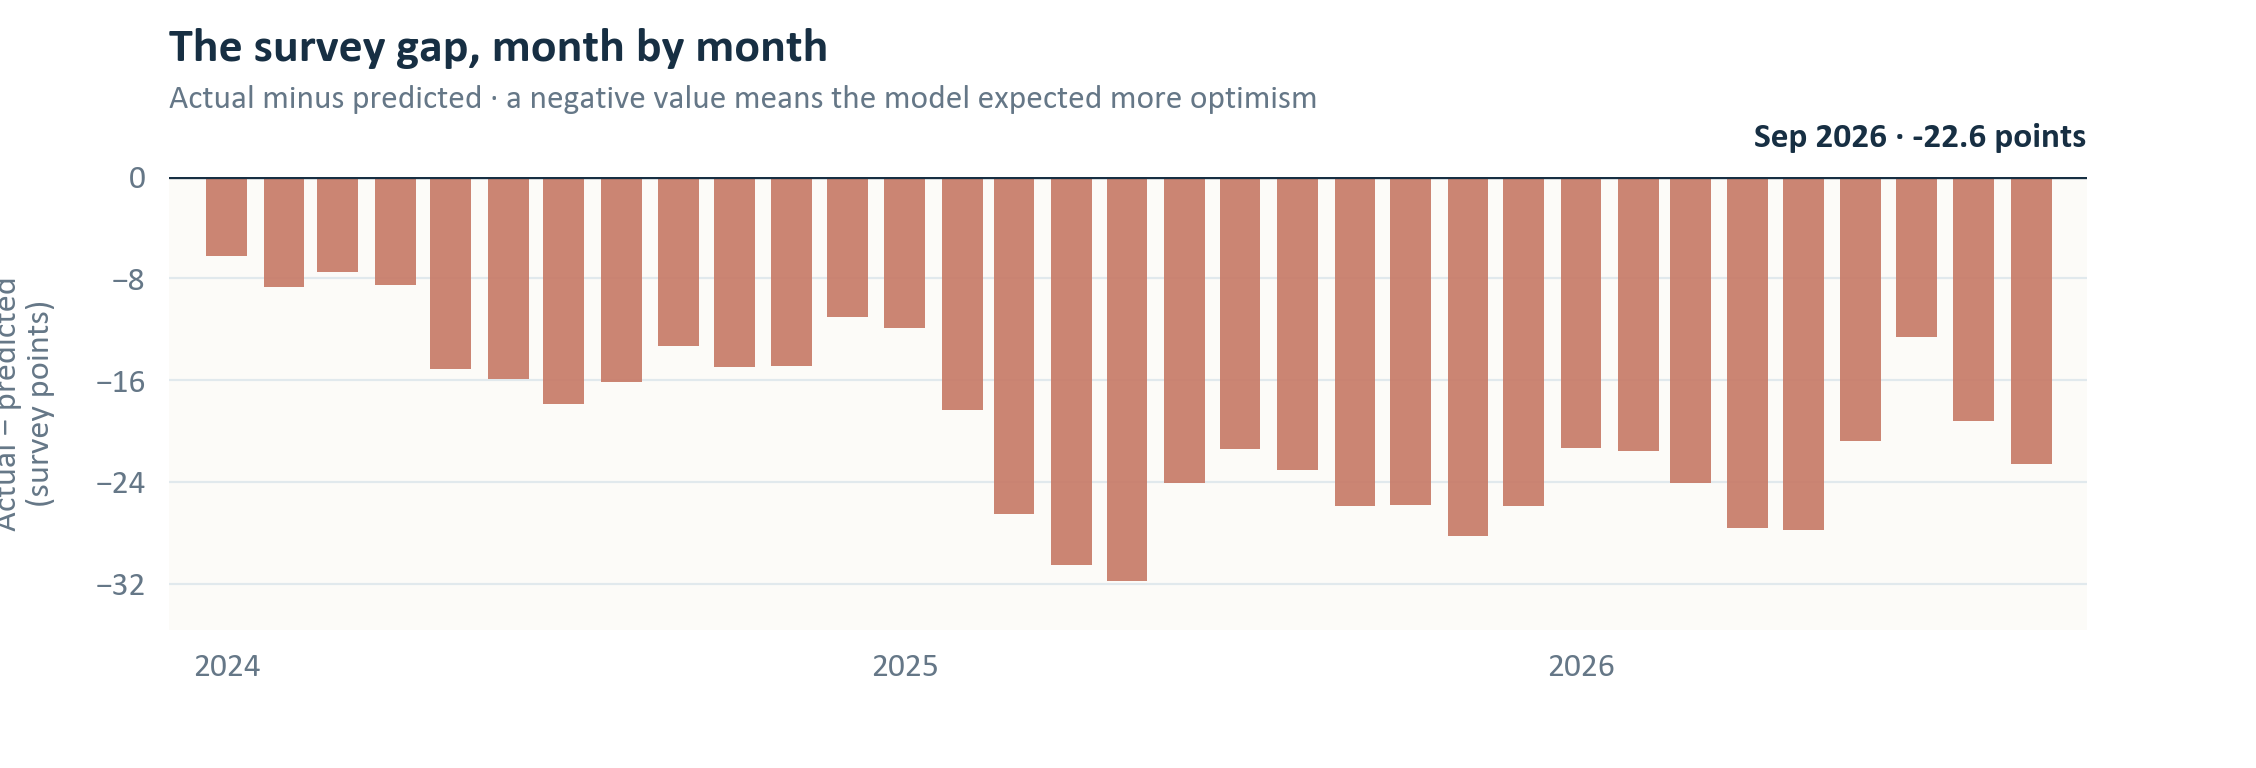

In [14]:
display(Image(filename=str(ROOT / 'outputs' / 'recent_gap.png')))

Each bar is actual sentiment minus M1’s earlier prediction. A bar below zero means M1 expected more optimism. It is not a percentage of irrational people or an estimated media effect.

Falling inflation does not mean prices returned to their old level. Suppose a basket rises from $100 to $110, then to $112.20. Inflation slows from 10% to 2%, but the basket still costs 12.2% more than before. We therefore add accumulated price increases and inflation-adjusted household income. Housing costs, debt, inequality and job insecurity can still be missing.

Adding these household measures lowers the long-period error score from 12.35 to 11.01 across 141 months. But in the 44 months with headline data, they score 12.01 versus 11.85 for M1. The benefit changes with the period. This does not identify one household pressure as the cause of the gap.

How the survey is collected can also matter. Michigan moved from phone to web, with web shares of 25%, 50%, 75% and 100% from April through July 2024. Allowing a gradual change over those months reduces September’s gap to −3.99; a model that also knows earlier sentiment gives −4.64 instead of M1’s −22.57. Many things changed at once, so this does not prove the survey switch caused the gap. Michigan’s revised July 2026 report still finds low sentiment when comparing the same collection methods.

Michigan reports differences by political affiliation, income and stock ownership. Its October description highlights lower-income households and smaller portfolios. These published summaries provide context, not individual records in our dataset. We cannot estimate what a particular political group read, believed or experienced.

One month’s sentiment is strongly related to the next: their correlation is 0.959 on a scale where +1 means a perfect positive relationship. That makes last month’s survey a demanding comparison. Two statistical checks warn that long-run relationships may shift; their full results are in the notebook. A separate test predicts monthly changes instead of levels. Adding headlines changes its error score from 4.2227 to 4.2234, with no reliable improvement.

## 5. What the headline sample represents

The sample runs from January 2020 through October 12, 2026: 81 complete months and an incomplete October. National sources are the Associated Press, Reuters and National Public Radio (NPR). Local sources are Gothamist, Texas Tribune and Colorado Sun. Hacker News supplies user-posted story titles. The same search topics cover the economy, inflation, jobs, wages, housing and living costs; searches do not ask only for bad news.

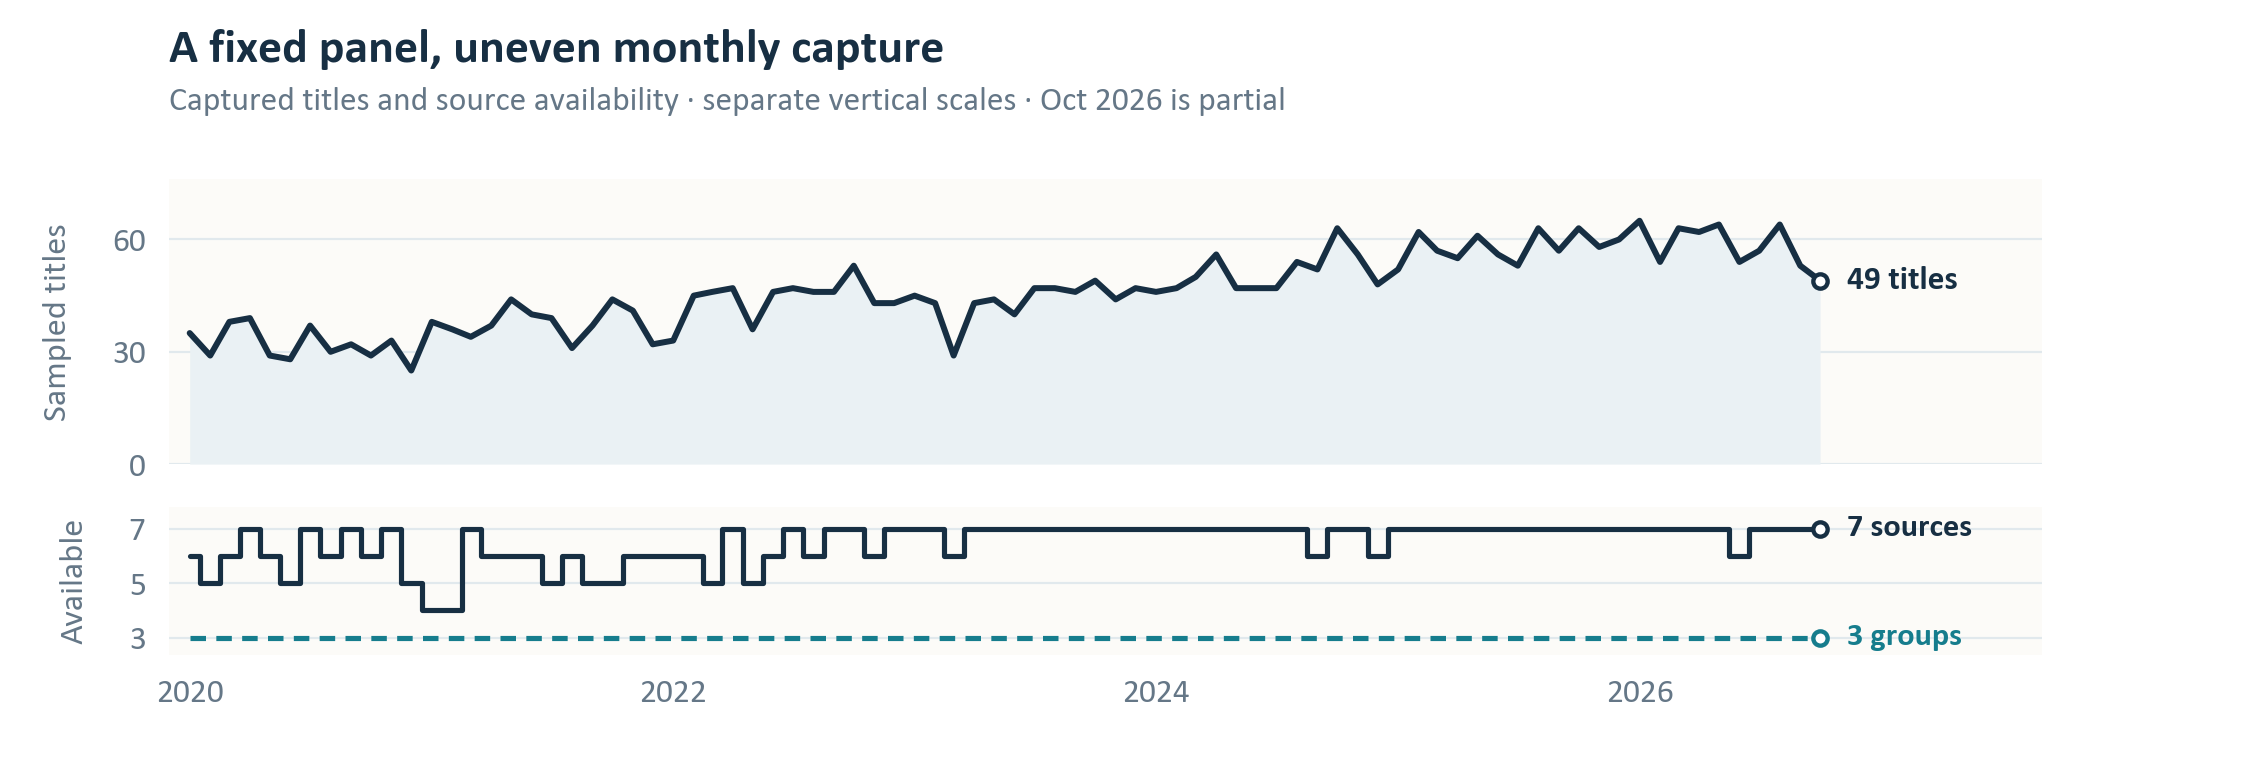

In [15]:
display(Image(filename=str(ROOT / 'outputs' / 'media_coverage.png')))

Top: number of captured titles. Bottom: number of available sources and source groups, using a different vertical scale. A missing source does not mean it published no economic news.

We measure titles, not complete articles, comments or what survey respondents actually saw. A repeatable computer rule selects at most twelve titles per source per month. First average titles within a source, then sources within each national/local/social group, then give each available group equal weight. A busy publisher therefore cannot dominate just by supplying more headlines.

We remove exact duplicates, repeated records, obvious promotions, wrong dates and clearly foreign-only titles. Similar rewritten stories, unknown geography and possible automated posts cannot all be resolved. Hacker News is a selected technology community, not a representative sample of American adults. A vote count seen at download time cannot tell us who saw the original post years earlier.

Search feeds rank and limit their results. Headlines can change or disappear, and missing sources can change the measured tone. Content supply means what is published; engagement means actions such as voting; exposure means what a person actually encounters. These are different. The dashboard shows source counts so readers can check whether a change in tone also reflects a change in the sample.

## 6. Turn wording into checkable measurements

In [16]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[6][1][0]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,What we measure,Plain meaning and boundary
0,Tone,How positive or negative the wording sounds. The model score is po...
1,Topic attention (salience),"How much of the captured coverage mentions jobs, layoffs, prices, ..."
2,Framing,Which aspect is emphasized: high prices versus slowing inflation; ...
3,Fact checking (calibration),"Compare a numerical claim with the right official measure, period ..."
4,Political credit/blame,Who is mentioned and who appears to receive credit or blame. Criti...


The coding guide was written before scoring; later changes to headline eligibility are documented. A fixed Cardiff language model reads words in context. We compare it with VADER, a word-list sentiment method. The model was not trained on Michigan survey outcomes. Word-match rules for topics, emotion, framing and blame remain rough indicators awaiting human checks.

Bad facts and emotional wording are different: "unemployment rose" can be an accurate, calmly worded report. A model released in 2022 also could not have been used in 2020. Our earlier text scores use that later tool and headlines retrieved now, so they are historical reconstructions, not proof of what a working system could have known then.

A fair comparison needs a reference. Page 11 compares providers covering the same official reports. It cannot make every truthful detail identical. Testing equal good/bad economic surprises would also need the forecasts people expected beforehand and a fuller record of what was published. Eight selected unemployment-title percentages match official releases, but incomplete definitions, periods and release times prevent a full accuracy judgment.

In [17]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[6][1][4]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Measurement,January–September 2026: average monthly result
0,Tone,Score -0.199; 30.2% negative; 6.5% flagged emotional words
1,Topic attention,22.7% housing; 5.7% wages; 1.9% layoffs; 1.6% hiring
2,Framing,24.1% price level versus 18.2% inflation rate; 7.4% household vers...
3,Political credit/blame,15.5% political mentions; 0.4% credit and 1.0% blame word matches


These results use 9 complete months and 536 titles. Each month and source group counts equally; topics can overlap. The 30.2% negative measure describes weighted headlines, not unhappy people. Negativity bias means giving bad news extra weight; availability bias means judging by what comes easily to mind; confirmation bias means favoring an existing belief; anchoring means relying on an earlier reference such as an old price. Titles alone cannot show these processes inside readers’ minds.

Changing political names switched 5/100 labels (average size of score change 0.076); adding a Gothamist name tag switched 12/100 labels (average size of score change 0.102), and a Reuters prefix 12/100 labels (average size of score change 0.083). The scoring therefore hides source names. A changed name can also change meaning, so these checks alone do not prove political unfairness.

## 7. What has and has not been checked

A label is a reviewer’s judgment, such as negative, neutral or positive. The assignment requires at least 300 items labeled independently by two people. Those completed human labels are unavailable. We prepared the worksheets and instructions and ran separate AI reviews, but machines do not replace the two required people. This is an unfinished assignment requirement.

In [18]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[7][1][1]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Check,Current status
0,300-item human packet,"Prepared with different item orders, hidden source/date informatio..."
1,Human agreement,Unavailable until both people judge the items independently.
2,Human-checked accuracy,Unavailable without reliable human reference answers. Matching a w...
3,Separate AI reviews,"Useful for finding possible errors; explicitly identified as AI, n..."
4,Fact-checking accuracy,No verified error rate for the full headline sample. Numerical cla...
5,Resolving disagreements,Save both original labels; a later reviewer records a reasoned fin...


For real human results, report both the share of matching answers and chance-adjusted agreement, called Cohen’s kappa. Precision asks how many items called negative really are negative; recall asks how many genuinely negative items were found. Their combined score is F1; macro-F1 gives each class equal weight. Report each class and source separately, because a strong overall average can hide poor results for one group.

A headline may quote someone, use sarcasm, or describe good national news alongside household hardship. Reviewers therefore keep a short quotation supporting their label and distinguish calm bad news from emotional wording. Mixed and uncertain cases need explicit treatment. After using reviews to improve a model, test it on new items that did not guide those changes.

The two AI reviews agree on 92.0% of the original 300 titles (chance-adjusted agreement, or kappa, 0.889). Later relevance checks retain 277 and exclude 23; original judgments are saved. The context-reading model matches both AI reviewers more often than the word list on the retained positive/neutral/negative items. Mixed or uncertain answers are left out of that comparison, not forced into a class. The notebook shows results for each class and source. Agreement between machines is not human-checked accuracy.

## 8. Do headlines improve the prediction?

We compare the same test months. M1 uses the economy only. M2 adds the previous month’s headline tone. M3 also adds household income and accumulated prices. These comparisons learn from February 2020 onward, using at least 36 earlier months. They differ from the longer-history M1 chart on page 4. A household-only addition and models using last month’s survey help show what actually adds information.

In the table, Months is the number of tests. RMSE is the error score defined on page 4. Mean absolute error (MAE) is the average size of the mistakes, ignoring their signs. Coverage is the share of answers inside a range intended to cover 95%. Lower errors and coverage near 95% are better; a range can also be too wide to be useful.

In [19]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[8][1][2]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Forecast rule,Months,RMSE,MAE,Range coverage
0,Learn from last month’s survey,44,4.32,3.57,100.0%
1,Last survey + economy,44,4.66,3.91,95.5%
2,Last survey + economy + headlines,44,4.62,3.93,97.7%
3,Economy + household pressures,44,12.01,9.77,77.3%
4,M1: economy only,44,11.85,10.01,79.5%
5,M2: economy + headlines,44,11.85,10.07,81.8%
6,M3: add household pressures,44,11.95,9.82,77.3%
7,Repeat last month’s survey,44,4.27,3.54,—


Test months: 2023-02-01 to 2026-09-01. Across the same 44 test months, adding headline tone lowers the forecast-error score by 0.01 survey points. When the model also knows last month’s survey, headlines lower the score by 0.04 points.

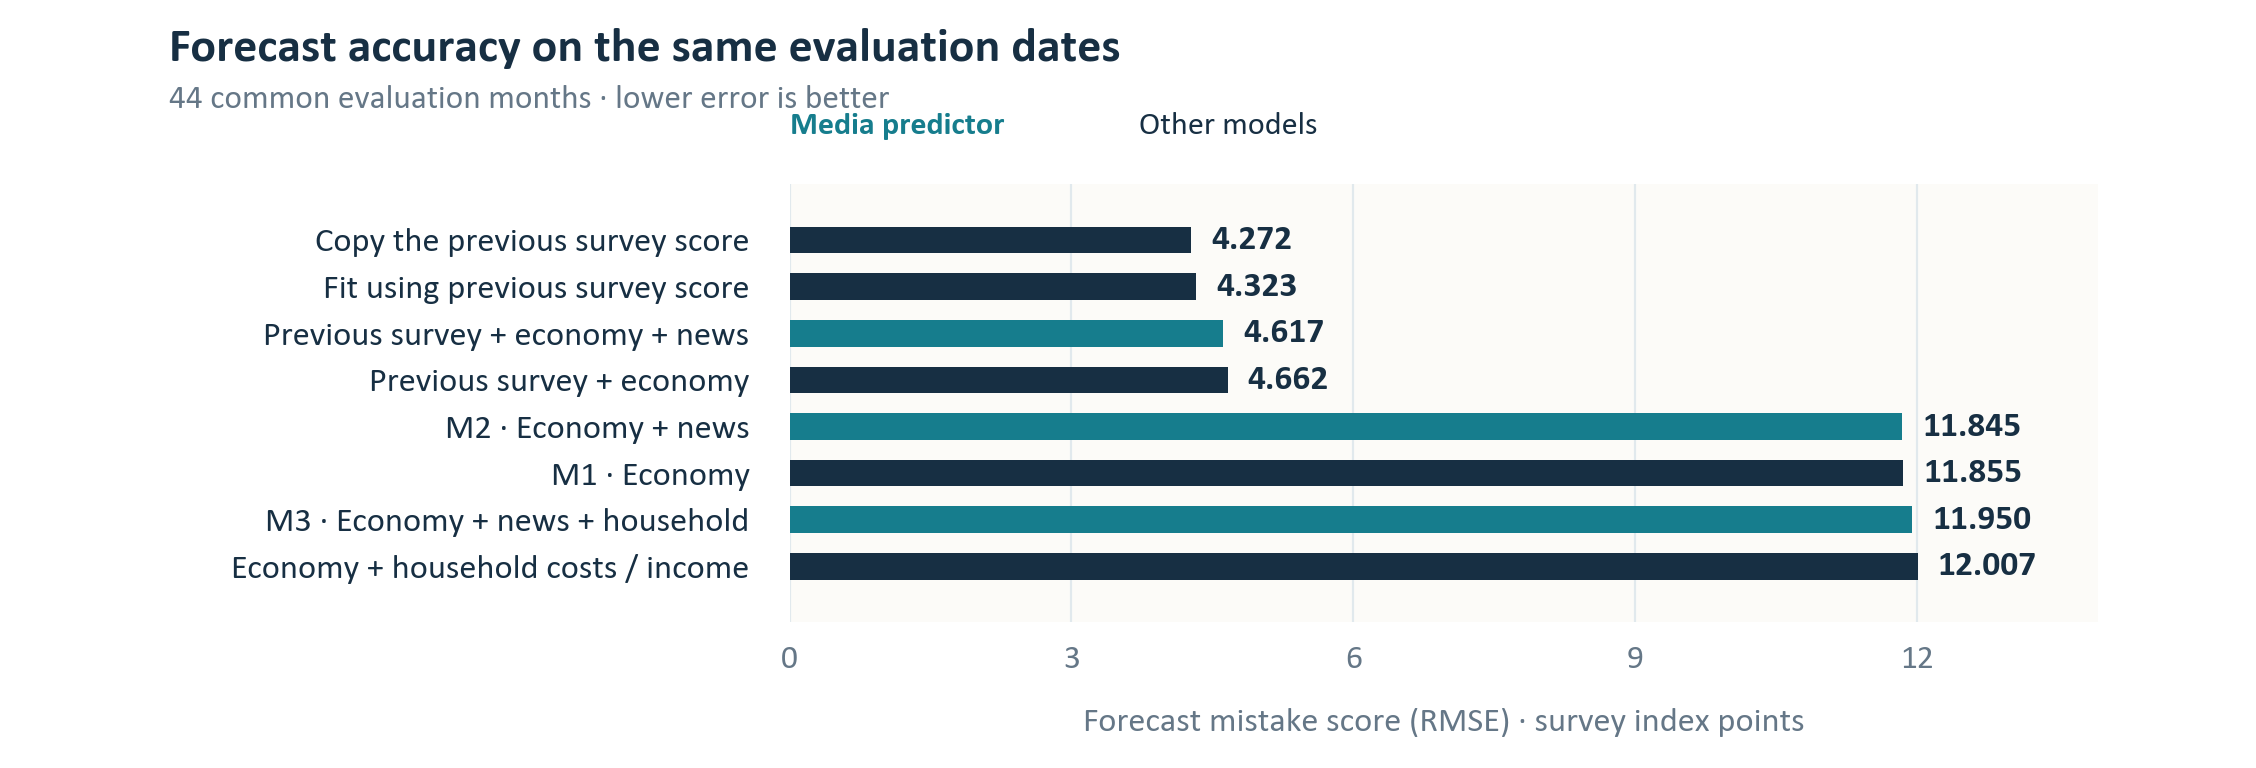

In [20]:
display(Image(filename=str(ROOT / 'outputs' / 'model_accuracy.png')))

Error scores for identical test months. Lower bars mean smaller mistakes. The very small gain from headlines does not show that headlines caused survey sentiment to fall.

M2 is rebuilt 44 times. A one-point increase in earlier tone changes its prediction by -1.57 to 17.54 survey points, depending on the learning period; the link is positive 37 times. Changing signs warn that the link is unstable. After allowing for three comparisons, statistical checks do not establish a reliable improvement. The notebook checks different time lags, sources and wording rules, and allows errors in nearby months to be related. Such calculations cannot fix a poorly specified model.

## 9. What would show cause and effect?

Two things moving together does not show which caused which. Job losses may worsen both news and sentiment. Worried readers may seek bad news, and publishers may respond to that demand. Political identity can affect both source choice and survey answers. Monthly national averages cannot separate these paths.

The assignment permits an observational study plus a detailed plan for a stronger test. We propose randomly assigning consenting people equally accurate summaries of the same report. One could emphasize high prices, another slowing inflation. Keep the numbers, source, length and reading difficulty the same. Measure beliefs, household outlook and recall before and after. Set the comparisons and sample-size calculation in advance and obtain required approval before recruitment. No participants were recruited here.

Random assignment makes the groups comparable on average. Check whether participants understood the framing without misunderstanding the facts. Count everyone in their originally assigned group, report who dropped out, and allow for testing several outcomes. An unrelated summary and a later follow-up help check alternative explanations. These are proposed procedures, not completed experimental results.

In [21]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[9][1][3]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Evidence against a media-bias explanation,What it would mean
0,Headlines add no reliable forecasting gain,The text may add little beyond economic conditions and last month’...
1,Household or survey-method checks shrink the gap,Everyday costs or measurement differences may explain it.
2,Negative headlines accurately describe bad outcomes,Reporting bad news does not establish distorted coverage.
3,Provider differences disappear after expected-news checks,Different surprises may explain different wording.
4,A large enough framing experiment finds no effect,The tested wording may not change beliefs through the proposed route.


Even a convincing experiment with volunteers would not establish an effect on the national Michigan score. We would also need to know what the wider population saw, recruit or reweight a representative sample, compare the same outcomes, and justify applying the result to other people. The detailed plan, including these assumptions, is in docs/causal_design.md.

## 10. Read the provider bars and trading risks

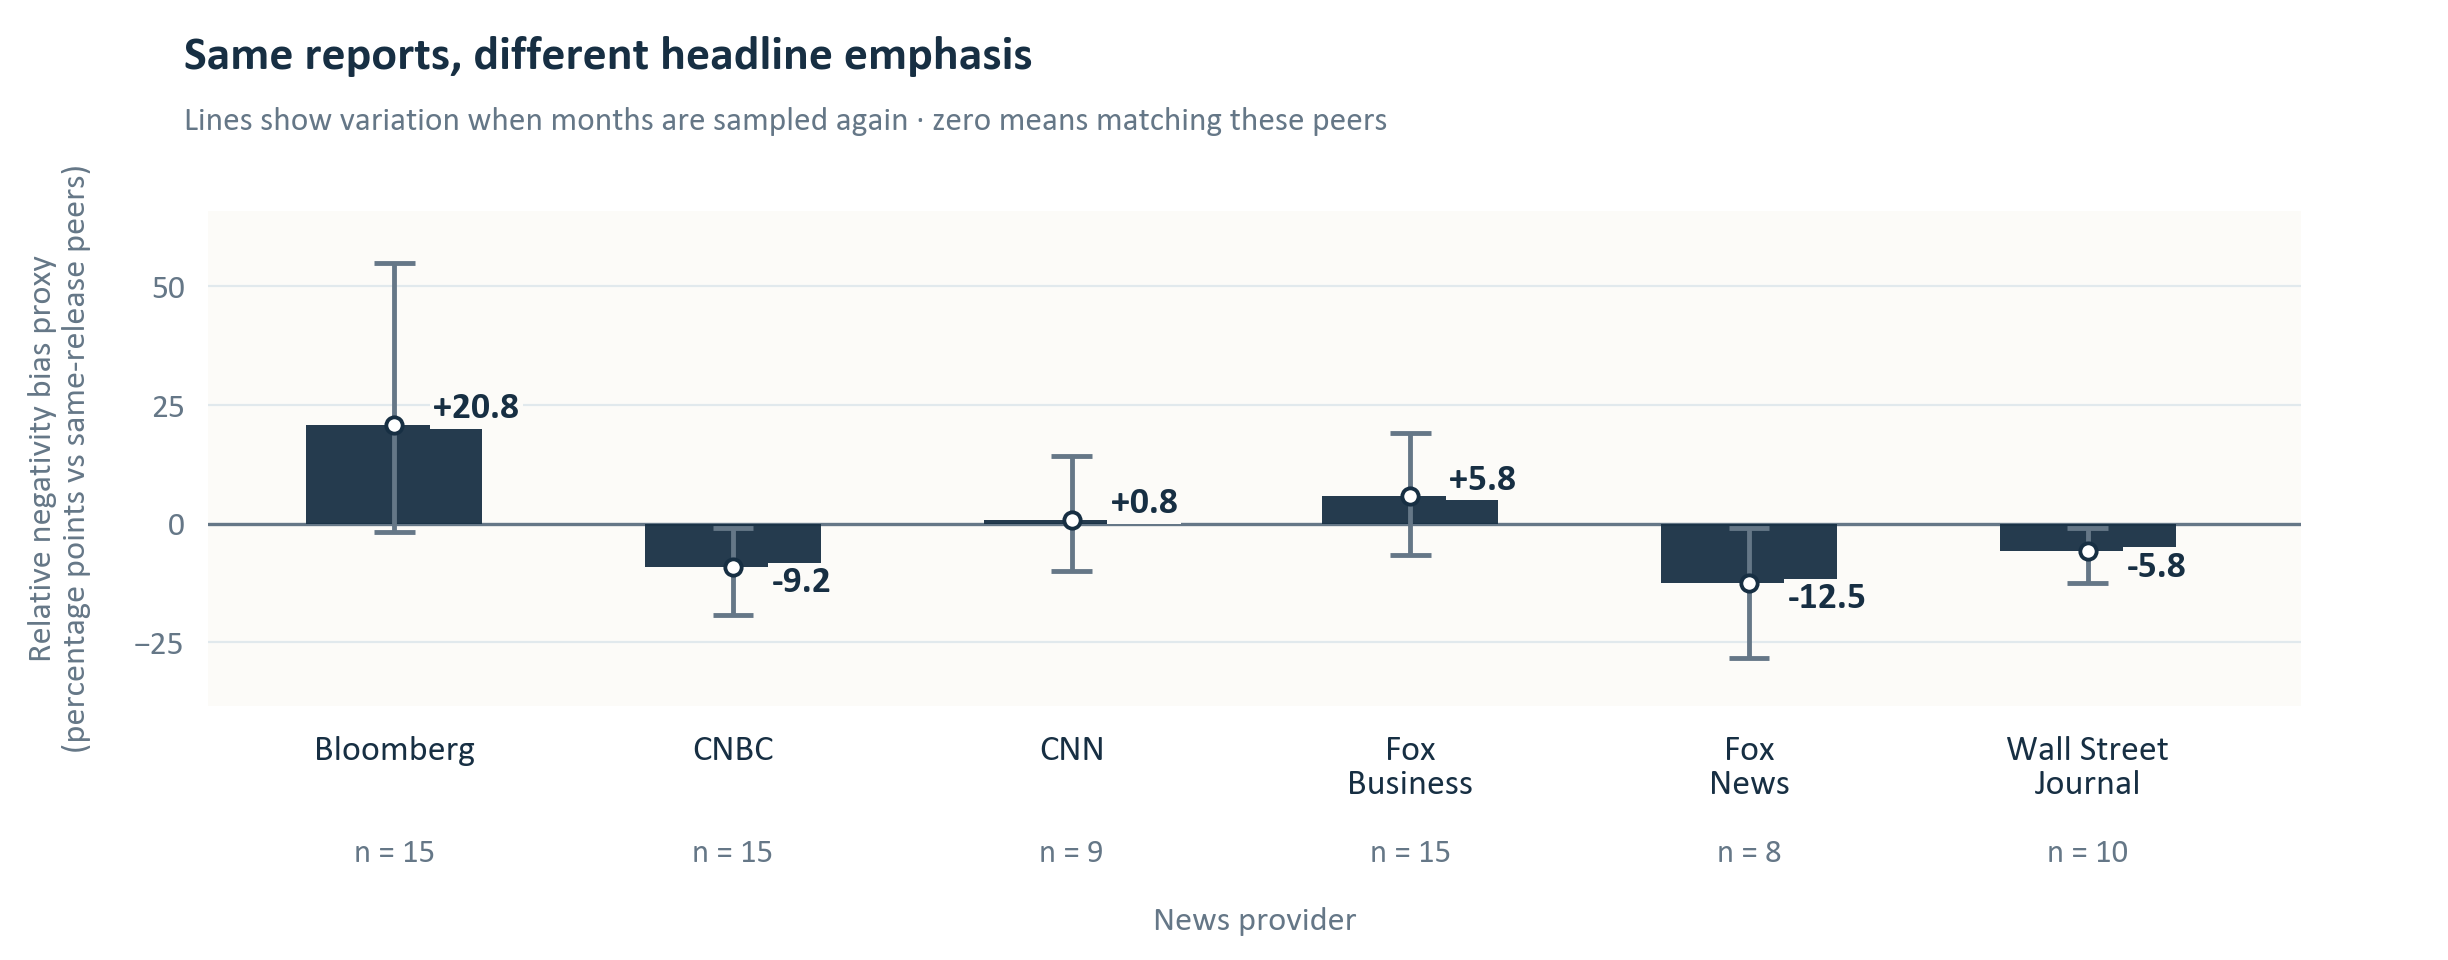

In [22]:
display(Image(filename=str(ROOT / 'outputs' / 'provider_bias.png')))

Same-event comparison: 6 providers, 6 reports and 72 headlines. The events are 5 jobs reports and 1 consumer-price report. Bars show extra negative-headline share compared with the other providers, in percentage points. Each report counts equally. The n labels count headlines. Lines show how results vary when the 6 months are repeatedly sampled; they leave out search and AI-label errors.

A provider with 40% negative headlines versus a 30% average for the others gets +10 percentage points: 40 minus 30. Zero means matching these peers, not perfect neutrality. Average within each provider/report first, compare with the other providers equally, then give each report equal weight. The lines show variation when months are sampled again; they omit search and AI-label errors.

The separate October 15, 2026 sample uses six providers and six shared reports. A documented change used coverage counts, not scores, after the original set shared only four. CNBC and the two Fox publications remain separate. Different truthful details can explain different wording; some signs change under other checks. Human validation is missing here, and the earlier AI review had no CNBC or Fox items. The bars do not measure lying, political loyalty or effects on readers.

Trading uses a different monthly news gap, B: average the negative-headline percentages for Reuters and NPR, then subtract Colorado Sun. These three sources supply 1,923 titles across 81 complete months; different stories and audiences can explain their differences. Compare last month’s B with the median of the twelve months before it. The median is the middle value after sorting; for twelve values, average the middle two. This news gap never uses the Michigan survey gap.

Stocks are ownership shares in companies. An exchange-traded fund (ETF) is a basket of investments traded like a stock. The S&P 500 tracks roughly 500 large American companies; SPY is an ordinary fund tracking it. UPRO aims for three times its daily move; SPXU aims for the opposite three-times daily move. A 1% index rise means targets near +3% and -3%, respectively. BIL lends to the U.S. government for short periods. The aggressive funds magnify exposure internally even though this simulated account does not borrow.

The three-times target resets every day. If the index rises 10% and then falls 9.09%, it returns to its start; an ideal three-times upward fund instead loses about 5.45%, before fees. It is not three times the whole-period return. Nearly all invested money can be lost. Yearly growth below is the constant annual rate connecting start and finish, not the gain every year. Worst fall means the largest drop from an earlier peak, not from the starting balance.

The dashboard preserves the October 13 economic snapshot, with survey, forecasts and missing-source checks. October 23’s final survey and October 29’s price/output releases remain later updates; election timing alone establishes no cause.

## 11. Answers and three text-only trading tests

In [23]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[11][1][0]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Required question,What the evidence supports
0,How measure coverage bias?,"Compare the same events; separate tone, topics, framing, facts and..."
1,Impact on Michigan sentiment?,A forecasting link does not show that news caused the national sco...
2,How much does the economy explain?,The three inputs leave large errors; last month’s survey often pre...
3,Which thinking biases are measurable?,"We see wording, not readers’ attention, memory or beliefs. Individ..."
4,Do headlines improve predictions?,"Only tiny, statistically unreliable gains on matching test months."
5,What would contradict a media explanation?,"Household costs explaining the gap, accurate negative reporting, o..."


Only the news gap B chooses these trades. Fade buys the three-times up fund above usual and the down fund below usual. Follow reverses those choices. Wait buys up only when B is above usual but falling, or down when below usual but rising; otherwise it holds the bill fund. A news gap equal to usual, or missing inputs, means bills for all three. The choices never use economic statistics, survey scores or price trends.

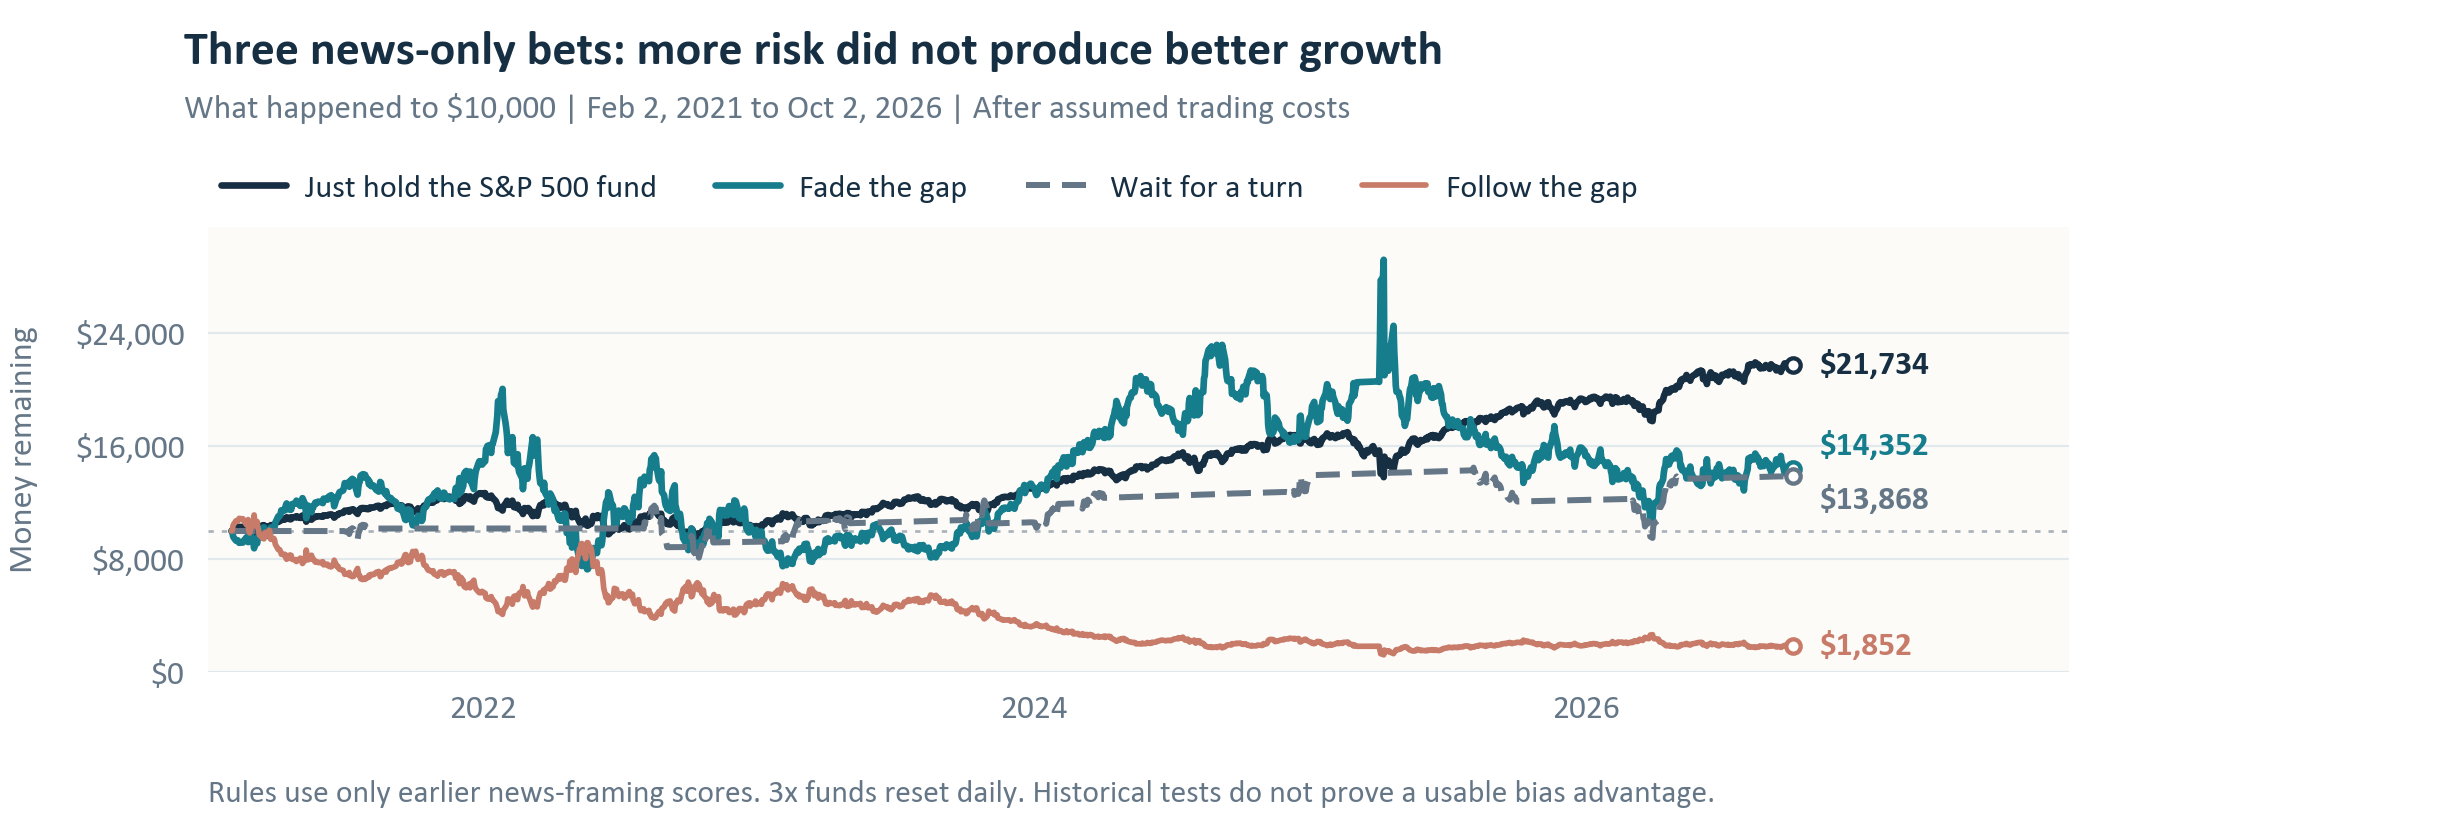

In [24]:
display(Image(filename=str(ROOT / 'outputs' / 'bias_trading.png')))

October 17, 2026 final revision, after the October 13 economic cutoff. Historical simulation: February 2, 2021 to October 2, 2026. Monthly choices use completed earlier headlines and start earning returns after execution at the first shared-session close after the first calendar day.

In [25]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[11][1][3]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Rule: same dates/costs,"End from $10,000",Yearly growth,Worst fall
0,Fade the gap,"$14,352",6.59%,63.73%
1,Follow the gap,"$1,852",-25.76%,89.07%
2,Wait for a turn,"$13,868",5.94%,34.43%
3,Hold ordinary stock fund,"$21,734",14.70%,24.50%


Costs are 0.10% per purchase or sale: $1 per $1,000 traded, charged on both legs of a switch and at entry/final exit. Gains include approximated reinvested distributions. Two rules made money, yet all three grew less and fell more than the ordinary stock fund. Waiting held bills in 55 of 68 decisions. Historical profit alone does not make these better investments.

Rules were fixed before calculating these returns, after earlier findings were known. Reconstructed headlines, later software and revised prices prevent a claim that these signals were available then. Human validation, taxes, market impact and an untouched future test are missing. Full rules and comparisons: docs/BIAS_TRADING_PROTOCOL.md; older allocation tests remain in the notebook.

Sources: [Michigan](https://www.sca.isr.umich.edu/), [BLS](https://www.bls.gov/cps/), [BEA](https://www.bea.gov/data), [ALFRED](https://alfred.stlouisfed.org/), [CardiffNLP](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest), [VADER](https://github.com/cjhutto/vaderSentiment), [ProShares](https://www.proshares.com/our-etfs/leveraged-and-inverse/upro); [Budak et al. (2016)](https://5harad.com/papers/mediabias.pdf), [Gentzkow-Shapiro (2010)](https://web.stanford.edu/~gentzkow/research/biasmeas.pdf). Full references and methods: docs/sources.md and protocols. Terms: docs/READING_GUIDE.md. AI help: AI_USE.md.

## Reproducibility and limitations

See `README.md`, `SNAPSHOT.md`, `AI_USE.md`, the source manifest, codebook, causal proposal, and annotation-validation protocol. A fresh download can change mutable feed results. Saved aggregate outputs preserve this snapshot, while item-level data remain local.